In [ ]:
# Assignment # 1
## Data Science Tools & Techniques
### MS Data Science

**Name:** Romana Javed  
**Roll Number:** 26i-8008  
**Section:** MSDS

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:

df = pd.read_csv("Dataset2.csv")

df.head()

,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
0,1,63,Female,Masters,Married,Unemployed,Other-service,57,28219,7604,us,80471,denied,26,1,21.1,occasional,medium,759,0
1,2,20,Female,PhD,Married,Government,NaN,98,26959,8738,NaN,83789,approved,34,3,23.9,smoker,low,730,0
2,3,46,Female,Bachelors,Divorced,Unemployed,Tech-support,8,15621,7180,India,93380,approved,5,4,28.4,non-smoker,low,460,0
3,4,52,Other,Masters,Single,Government,Other-service,9,26022,8588,us,41035,denied,19,5,26.6,occasional,medium,464,0
4,5,56,Female,Masters,Single,Self-Employed,Prof-specialty,49,3075,2399,UK,69893,denied,19,1,24.5,smoker,high,NaN,0


In [ ]:
### Initial Inspection

In [6]:
df.shape

(5050, 20)

In [8]:
df.columns

Index(['id', 'age', 'gender', 'education', 'marital_status', 'workclass',
       'occupation', 'hours_per_week', 'capital_gain', 'capital_loss',
       'native_country', 'annual_income', 'loan_status', 'experience_years',
       'job_satisfaction', 'bmi', 'smoking_status', 'physical_activity',
       'credit_score', 'disease_risk'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5050 non-null   int64  
 1   age                5050 non-null   int64  
 2   gender             5050 non-null   object 
 3   education          5050 non-null   object 
 4   marital_status     5050 non-null   object 
 5   workclass          4798 non-null   object 
 6   occupation         4798 non-null   object 
 7   hours_per_week     5050 non-null   int64  
 8   capital_gain       5050 non-null   int64  
 9   capital_loss       5050 non-null   int64  
 10  native_country     4796 non-null   object 
 11  annual_income      4799 non-null   object 
 12  loan_status        5050 non-null   object 
 13  experience_years   5050 non-null   int64  
 14  job_satisfaction   5050 non-null   int64  
 15  bmi                4800 non-null   float64
 16  smoking_status     5050 

In [10]:
df.head()

,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
0,1,63,Female,Masters,Married,Unemployed,Other-service,57,28219,7604,us,80471,denied,26,1,21.1,occasional,medium,759,0
1,2,20,Female,PhD,Married,Government,NaN,98,26959,8738,NaN,83789,approved,34,3,23.9,smoker,low,730,0
2,3,46,Female,Bachelors,Divorced,Unemployed,Tech-support,8,15621,7180,India,93380,approved,5,4,28.4,non-smoker,low,460,0
3,4,52,Other,Masters,Single,Government,Other-service,9,26022,8588,us,41035,denied,19,5,26.6,occasional,medium,464,0
4,5,56,Female,Masters,Single,Self-Employed,Prof-specialty,49,3075,2399,UK,69893,denied,19,1,24.5,smoker,high,NaN,0


In [11]:
df.tail()

,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
5045,3907,68,Female,Bachelors,Married,Private,Other-service,29,42164,864,USA,92036,denied,7,1,28.2,occasional,high,451,1
5046,3774,47,Female,PhD,Single,Government,Prof-specialty,51,25458,867,NaN,116184,approved,25,2,21.5,smoker,high,694,0
5047,4636,59,Female,Masters,Divorced,Private,Machine-op-inspct,18,14947,8539,Germany,101859,approved,3,5,26.7,non-smoker,medium,628,0
5048,3162,45,Female,High School,Single,Self-Employed,Other-service,86,5525,3114,Germany,72860,approved,18,3,27.7,occasional,medium,454,1
5049,2660,33,Female,Bachelors,Divorced,Government,Craft-repair,87,9193,333,Germany,73588,denied,8,1,22.5,non-smoker,medium,759,1


In [ ]:
## EDA Before Preprocessing

In [13]:
df.describe()

,id,age,hours_per_week,capital_gain,capital_loss,experience_years,job_satisfaction,bmi,disease_risk
count,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,4800.000000,5050.000000
mean,2498.039208,43.618812,53.851287,25520.049109,4935.994653,21.974455,3.010099,27.445521,0.311287
std,1444.697897,14.942891,33.205355,14473.176645,2919.033568,12.863496,1.418582,8.227729,0.463066
min,1.000000,18.000000,5.000000,3.000000,0.000000,0.000000,1.000000,9.200000,0.000000
25%,1244.250000,31.000000,29.000000,13292.250000,2381.250000,11.000000,2.000000,23.700000,0.000000
50%,2497.500000,43.500000,54.000000,25933.000000,4925.500000,22.000000,3.000000,27.100000,0.000000
75%,3748.750000,57.000000,77.000000,37748.500000,7461.750000,33.000000,4.000000,30.500000,1.000000
max,5000.000000,69.000000,391.000000,49994.000000,9998.000000,44.000000,5.000000,204.000000,1.000000


In [15]:
df.describe(include="all")

,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
count,5050.000000,5050.000000,5050,5050,5050,4798,4798,5050.000000,5050.000000,5050.000000,4796,4799,5050,5050.000000,5050.000000,4800.000000,5050,5050,4800,5050.000000
unique,NaN,NaN,3,4,4,4,7,NaN,NaN,NaN,8,4522,2,NaN,NaN,NaN,3,3,551,NaN
top,NaN,NaN,Female,PhD,Divorced,Unemployed,Sales,NaN,NaN,NaN,UK,unknown,approved,NaN,NaN,NaN,smoker,high,unknown,NaN
freq,NaN,NaN,2528,1303,1361,1233,718,NaN,NaN,NaN,632,101,2578,NaN,NaN,NaN,1723,1728,101,NaN
mean,2498.039208,43.618812,NaN,NaN,NaN,NaN,NaN,53.851287,25520.049109,4935.994653,NaN,NaN,NaN,21.974455,3.010099,27.445521,NaN,NaN,NaN,0.311287
std,1444.697897,14.942891,NaN,NaN,NaN,NaN,NaN,33.205355,14473.176645,2919.033568,NaN,NaN,NaN,12.863496,1.418582,8.227729,NaN,NaN,NaN,0.463066
min,1.000000,18.000000,NaN,NaN,NaN,NaN,NaN,5.000000,3.000000,0.000000,NaN,NaN,NaN,0.000000,1.000000,9.200000,NaN,NaN,NaN,0.000000
25%,1244.250000,31.000000,NaN,NaN,NaN,NaN,NaN,29.000000,13292.250000,2381.250000,NaN,NaN,NaN,11.000000,2.000000,23.700000,NaN,NaN,NaN,0.000000
50%,2497.500000,43.500000,NaN,NaN,NaN,NaN,NaN,54.000000,25933.000000,4925.500000,NaN,NaN,NaN,22.000000,3.000000,27.100000,NaN,NaN,NaN,0.000000
75%,3748.750000,57.000000,NaN,NaN,NaN,NaN,NaN,77.000000,37748.500000,7461.750000,NaN,NaN,NaN,33.000000,4.000000,30.500000,NaN,NaN,NaN,1.000000


In [18]:
df.isnull().sum()

id                     0
age                    0
gender                 0
education              0
marital_status         0
workclass            252
occupation           252
hours_per_week         0
capital_gain           0
capital_loss           0
native_country       254
annual_income        251
loan_status            0
experience_years       0
job_satisfaction       0
bmi                  250
smoking_status         0
physical_activity      0
credit_score         250
disease_risk           0
dtype: int64

In [24]:
(df.isnull().sum() / len(df)) * 100

id                   0.000000
age                  0.000000
gender               0.000000
education            0.000000
marital_status       0.000000
workclass            4.990099
occupation           4.990099
hours_per_week       0.000000
capital_gain         0.000000
capital_loss         0.000000
native_country       5.029703
annual_income        4.970297
loan_status          0.000000
experience_years     0.000000
job_satisfaction     0.000000
bmi                  4.950495
smoking_status       0.000000
physical_activity    0.000000
credit_score         4.950495
disease_risk         0.000000
dtype: float64

In [25]:
df.duplicated().sum()

49

In [ ]:
### Identified Data Quality Issues

The dataset may contain:

- Missing values
- Blank entries
- Unknown values
- Inconsistent categorical values
- Outliers
- Invalid or unrealistic numerical values
- Possible duplicate rows

In [26]:
df.isnull().sum()

id                     0
age                    0
gender                 0
education              0
marital_status         0
workclass            252
occupation           252
hours_per_week         0
capital_gain           0
capital_loss           0
native_country       254
annual_income        251
loan_status            0
experience_years       0
job_satisfaction       0
bmi                  250
smoking_status         0
physical_activity      0
credit_score         250
disease_risk           0
dtype: int64

In [28]:
for column in df.columns:
    print(column)
    print(df[column].unique()[:20])
    print()

id
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]

age
[63 20 46 52 56 35 37 60 40 51 50 67 65 27 64 43 32 54 34 22]

gender
['Female' 'Other' 'Male']

education
['Masters' 'PhD' 'Bachelors' 'High School']

marital_status
['Married' 'Divorced' 'Single' 'Widowed']

workclass
['Unemployed' 'Government' 'Self-Employed' 'Private' nan]

occupation
['Other-service' nan 'Tech-support' 'Prof-specialty' 'Exec-managerial'
 'Machine-op-inspct' 'Sales' 'Craft-repair']

hours_per_week
[57 98  8  9 49 80 65 41 35 38 81 23 30 74 88 22 18 76 70 86]

capital_gain
[28219 26959 15621 26022  3075 12092 28343 43788  8495 47716  5366 36780
 14477 19346  4136 14435 26349 27160 24768  2075]

capital_loss
[7604 8738 7180 8588 2399 2280 9356 1951  522 3620 2680 4618 5806 6089
 3887 4976 1274  129 6910 3610]

native_country
['us' nan 'India' 'UK' 'Mexico' 'USA' 'Canada' 'Germany' 'U.S.']

annual_income
['80471' '83789' '93380' '41035' '69893' '111543' '66828' '38590' '62033'
 '62193' '88142' '9211

In [30]:
df = df.replace(["unknown", "Unknown", ""], np.nan)

In [31]:
df.isnull().sum()

id                     0
age                    0
gender                 0
education              0
marital_status         0
workclass            252
occupation           252
hours_per_week         0
capital_gain           0
capital_loss           0
native_country       254
annual_income        352
loan_status            0
experience_years       0
job_satisfaction       0
bmi                  250
smoking_status         0
physical_activity      0
credit_score         351
disease_risk           0
dtype: int64

In [32]:
categorical_columns = df.select_dtypes(include=['object']).columns
categorical_columns

Index(['gender', 'education', 'marital_status', 'workclass', 'occupation',
       'native_country', 'annual_income', 'loan_status', 'smoking_status',
       'physical_activity', 'credit_score'],
      dtype='object')

In [33]:
numerical_columns = df.select_dtypes(include=np.number).columns
numerical_columns

Index(['id', 'age', 'hours_per_week', 'capital_gain', 'capital_loss',
       'experience_years', 'job_satisfaction', 'bmi', 'disease_risk'],
      dtype='object')

In [34]:
df['native_country'].value_counts(dropna=False)

native_country
UK         632
us         613
USA        606
Germany    606
Canada     604
U.S.       590
Mexico     576
India      569
NaN        254
Name: count, dtype: int64

In [35]:
df['native_country'] = df['native_country'].replace({
    'USA': 'United States',
    'U.S.': 'United States',
    'us': 'United States'
})

In [36]:
df['native_country'].value_counts()

native_country
United States    1809
UK                632
Germany           606
Canada            604
Mexico            576
India             569
Name: count, dtype: int64

In [37]:
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

In [38]:
for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [39]:
df.isnull().sum()

id                   0
age                  0
gender               0
education            0
marital_status       0
workclass            0
occupation           0
hours_per_week       0
capital_gain         0
capital_loss         0
native_country       0
annual_income        0
loan_status          0
experience_years     0
job_satisfaction     0
bmi                  0
smoking_status       0
physical_activity    0
credit_score         0
disease_risk         0
dtype: int64

In [41]:
df_encoded = pd.get_dummies(df, columns=categorical_columns, drop_first=True)

In [42]:
df_encoded.head()

,id,age,hours_per_week,capital_gain,capital_loss,experience_years,job_satisfaction,bmi,disease_risk,gender_Male,...,credit_score_840,credit_score_841,credit_score_842,credit_score_843,credit_score_844,credit_score_845,credit_score_846,credit_score_847,credit_score_848,credit_score_849
0,1,63,57,28219,7604,26,1,21.1,0,False,...,False,False,False,False,False,False,False,False,False,False
1,2,20,98,26959,8738,34,3,23.9,0,False,...,False,False,False,False,False,False,False,False,False,False
2,3,46,8,15621,7180,5,4,28.4,0,False,...,False,False,False,False,False,False,False,False,False,False
3,4,52,9,26022,8588,19,5,26.6,0,False,...,False,False,False,False,False,False,False,False,False,False
4,5,56,49,3075,2399,19,1,24.5,0,False,...,False,False,False,False,False,False,False,False,False,False


In [43]:
df_encoded.shape

(5050, 5105)

In [44]:
df[numerical_columns].describe()

,id,age,hours_per_week,capital_gain,capital_loss,experience_years,job_satisfaction,bmi,disease_risk
count,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000
mean,2498.039208,43.618812,53.851287,25520.049109,4935.994653,21.974455,3.010099,27.428416,0.311287
std,1444.697897,14.942891,33.205355,14473.176645,2919.033568,12.863496,1.418582,8.021797,0.463066
min,1.000000,18.000000,5.000000,3.000000,0.000000,0.000000,1.000000,9.200000,0.000000
25%,1244.250000,31.000000,29.000000,13292.250000,2381.250000,11.000000,2.000000,23.900000,0.000000
50%,2497.500000,43.500000,54.000000,25933.000000,4925.500000,22.000000,3.000000,27.100000,0.000000
75%,3748.750000,57.000000,77.000000,37748.500000,7461.750000,33.000000,4.000000,30.300000,1.000000
max,5000.000000,69.000000,391.000000,49994.000000,9998.000000,44.000000,5.000000,204.000000,1.000000


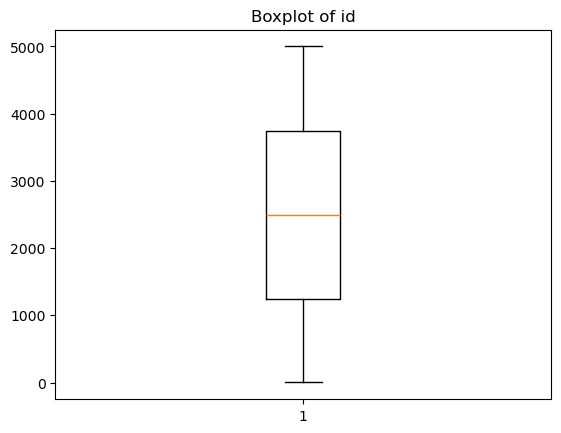

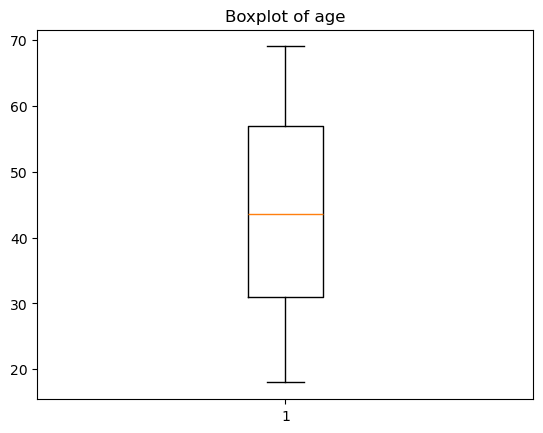

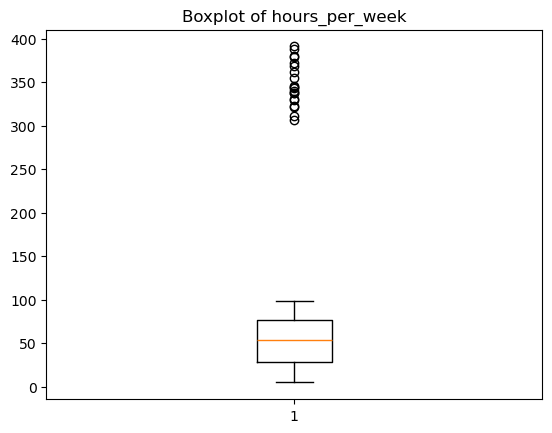

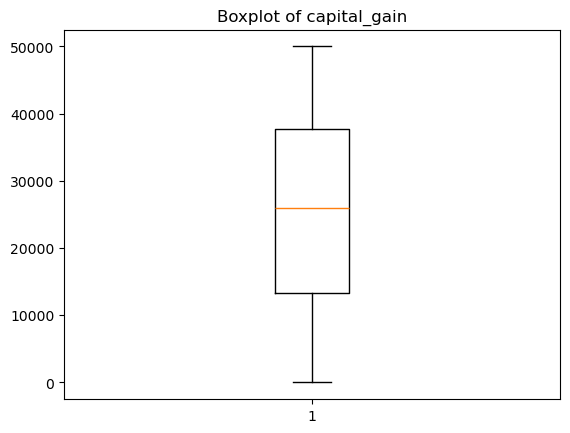

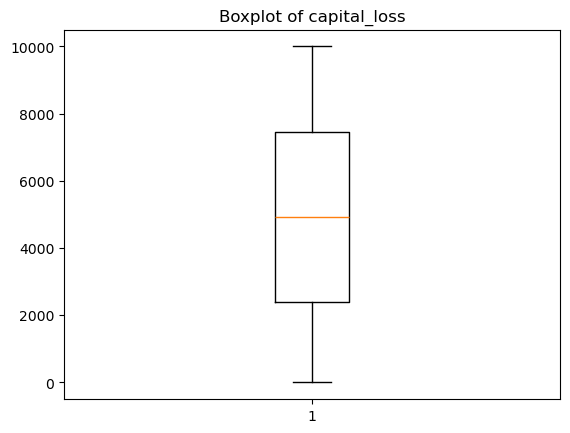

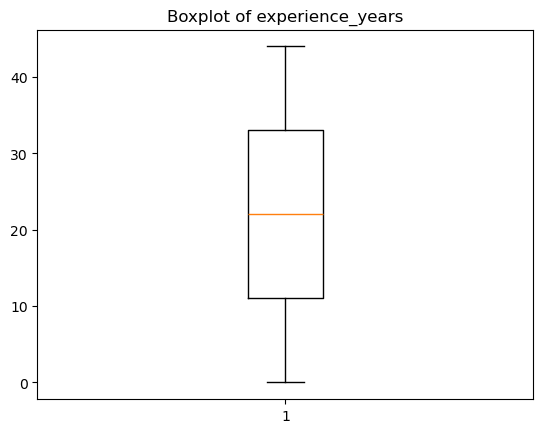

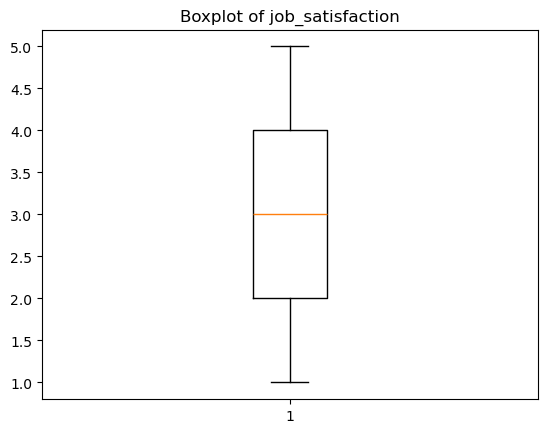

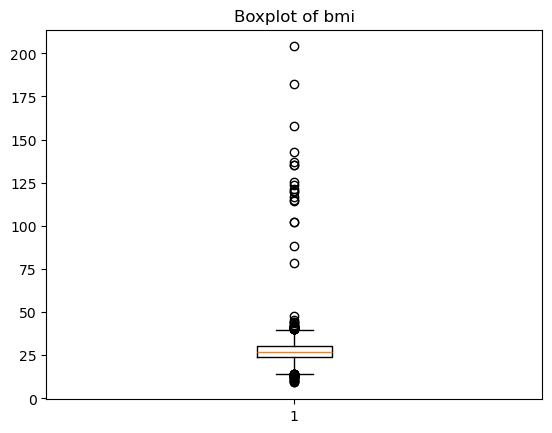

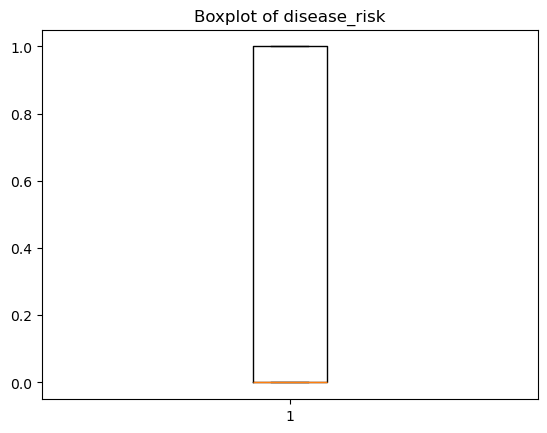

In [45]:
for col in numerical_columns:
    plt.figure()
    plt.boxplot(df[col].dropna())
    plt.title(f'Boxplot of {col}')
    plt.show()

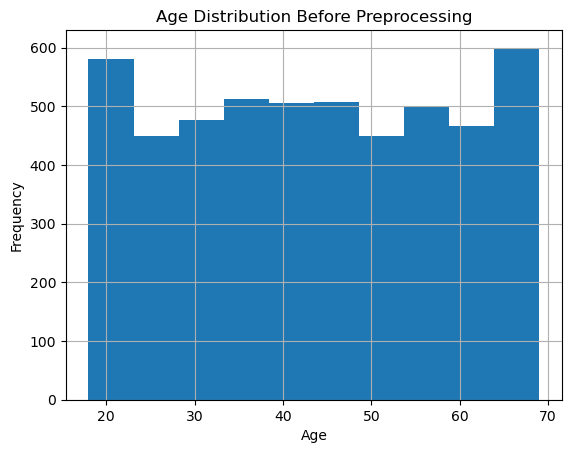

In [46]:
df['age'].hist()
plt.title('Age Distribution Before Preprocessing')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

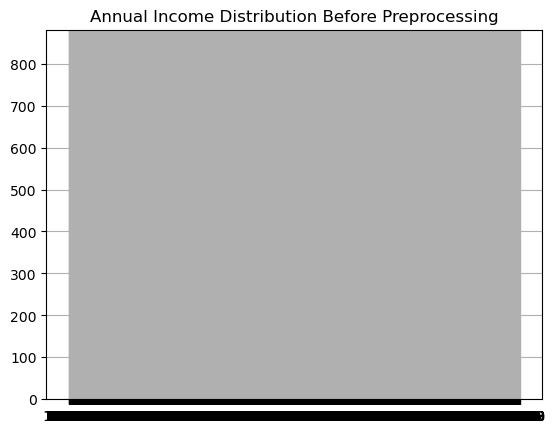

In [48]:
df['annual_income'].hist()
plt.title('Annual Income Distribution Before Preprocessing')
plt.show()

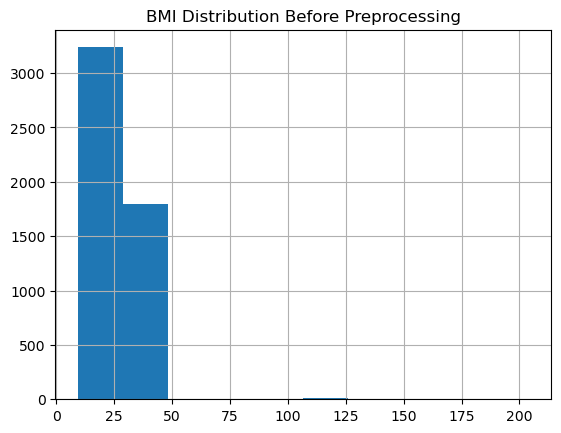

In [49]:
df['bmi'].hist()
plt.title('BMI Distribution Before Preprocessing')
plt.show()

In [ ]:
## EDA After Preprocessing

In [50]:
df.describe()

,id,age,hours_per_week,capital_gain,capital_loss,experience_years,job_satisfaction,bmi,disease_risk
count,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000,5050.000000
mean,2498.039208,43.618812,53.851287,25520.049109,4935.994653,21.974455,3.010099,27.428416,0.311287
std,1444.697897,14.942891,33.205355,14473.176645,2919.033568,12.863496,1.418582,8.021797,0.463066
min,1.000000,18.000000,5.000000,3.000000,0.000000,0.000000,1.000000,9.200000,0.000000
25%,1244.250000,31.000000,29.000000,13292.250000,2381.250000,11.000000,2.000000,23.900000,0.000000
50%,2497.500000,43.500000,54.000000,25933.000000,4925.500000,22.000000,3.000000,27.100000,0.000000
75%,3748.750000,57.000000,77.000000,37748.500000,7461.750000,33.000000,4.000000,30.300000,1.000000
max,5000.000000,69.000000,391.000000,49994.000000,9998.000000,44.000000,5.000000,204.000000,1.000000


In [51]:
df.isnull().sum()

id                   0
age                  0
gender               0
education            0
marital_status       0
workclass            0
occupation           0
hours_per_week       0
capital_gain         0
capital_loss         0
native_country       0
annual_income        0
loan_status          0
experience_years     0
job_satisfaction     0
bmi                  0
smoking_status       0
physical_activity    0
credit_score         0
disease_risk         0
dtype: int64

In [52]:
df_encoded.head()

,id,age,hours_per_week,capital_gain,capital_loss,experience_years,job_satisfaction,bmi,disease_risk,gender_Male,...,credit_score_840,credit_score_841,credit_score_842,credit_score_843,credit_score_844,credit_score_845,credit_score_846,credit_score_847,credit_score_848,credit_score_849
0,1,63,57,28219,7604,26,1,21.1,0,False,...,False,False,False,False,False,False,False,False,False,False
1,2,20,98,26959,8738,34,3,23.9,0,False,...,False,False,False,False,False,False,False,False,False,False
2,3,46,8,15621,7180,5,4,28.4,0,False,...,False,False,False,False,False,False,False,False,False,False
3,4,52,9,26022,8588,19,5,26.6,0,False,...,False,False,False,False,False,False,False,False,False,False
4,5,56,49,3075,2399,19,1,24.5,0,False,...,False,False,False,False,False,False,False,False,False,False


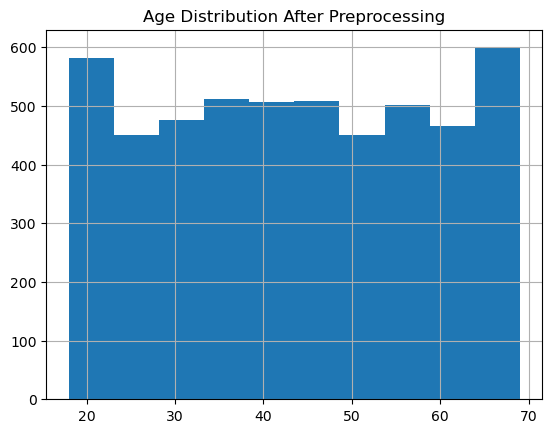

In [53]:
df['age'].hist()
plt.title('Age Distribution After Preprocessing')
plt.show()

In [ ]:
## Dataset 1: Census-Income Dataset

This section performs data preprocessing and exploratory data analysis
(EDA) on the Census-Income dataset before and after preprocessing.

In [55]:
census_df = pd.read_csv("census-income.csv")

census_df.head()

,age,class_of_worker,detailed_industry_recode,detailed_occupation_recode,education,wage_per_hour,enroll_in_edu_inst_last_wk,marital_status,major_industry_code,major_occupation_code,...,country_of_birth_father,country_of_birth_mother,country_of_birth_self,citizenship,own_business_or_self_employed,fill_inc_questionnaire_for_veteran_admin,veterans_benefits,weeks_worked_in_year,year,income_class
0,73,Not in universe,0,0,High school graduate,0,Not in universe,Widowed,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,2.0,0.0,95.0,- 50000.
1,58,Self-employed-not incorporated,4,34,Some college but no degree,0,Not in universe,Divorced,Construction,Precision production craft & repair,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,2.0,52.0,94.0,- 50000.
2,18,Not in universe,0,0,10th grade,0,High school,Never married,Not in universe or children,Not in universe,...,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0.0,Not in universe,2.0,0.0,95.0,- 50000.
3,9,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,0.0,0.0,94.0,- 50000.
4,10,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,0.0,0.0,94.0,- 50000.


In [56]:
### Initial Dataset Inspection

In [57]:
print("Number of rows:", census_df.shape[0])
print("Number of columns:", census_df.shape[1])

Number of rows: 22150
Number of columns: 42


In [58]:
census_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22150 entries, 0 to 22149
Data columns (total 42 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   age                                       22150 non-null  int64  
 1   class_of_worker                           22150 non-null  object 
 2   detailed_industry_recode                  22150 non-null  int64  
 3   detailed_occupation_recode                22150 non-null  int64  
 4   education                                 22150 non-null  object 
 5   wage_per_hour                             22150 non-null  int64  
 6   enroll_in_edu_inst_last_wk                22149 non-null  object 
 7   marital_status                            22149 non-null  object 
 8   major_industry_code                       22149 non-null  object 
 9   major_occupation_code                     22149 non-null  object 
 10  race                              

In [59]:
census_df.columns

Index(['age', 'class_of_worker', 'detailed_industry_recode',
       'detailed_occupation_recode', 'education', 'wage_per_hour',
       'enroll_in_edu_inst_last_wk', 'marital_status', 'major_industry_code',
       'major_occupation_code', 'race', 'hispanic_origin', 'sex',
       'member_of_a_labor_union', 'reason_for_unemployment',
       'full_or_part_time_employment_stat', 'capital_gains', 'capital_losses',
       'dividends_from_stocks', 'tax_filer_status',
       'region_of_previous_residence', 'state_of_previous_residence',
       'detailed_household_and_family_stat',
       'detailed_household_summary_in_household', 'instance_weight',
       'migration_code_change_in_msa', 'migration_code_change_in_reg',
       'migration_code_move_within_reg', 'live_in_this_house_1_year_ago',
       'migration_prev_res_in_sunbelt', 'num_persons_worked_for_employer',
       'family_members_under_18', 'country_of_birth_father',
       'country_of_birth_mother', 'country_of_birth_self', 'citizenship

In [60]:
census_df.head()

,age,class_of_worker,detailed_industry_recode,detailed_occupation_recode,education,wage_per_hour,enroll_in_edu_inst_last_wk,marital_status,major_industry_code,major_occupation_code,...,country_of_birth_father,country_of_birth_mother,country_of_birth_self,citizenship,own_business_or_self_employed,fill_inc_questionnaire_for_veteran_admin,veterans_benefits,weeks_worked_in_year,year,income_class
0,73,Not in universe,0,0,High school graduate,0,Not in universe,Widowed,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,2.0,0.0,95.0,- 50000.
1,58,Self-employed-not incorporated,4,34,Some college but no degree,0,Not in universe,Divorced,Construction,Precision production craft & repair,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,2.0,52.0,94.0,- 50000.
2,18,Not in universe,0,0,10th grade,0,High school,Never married,Not in universe or children,Not in universe,...,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0.0,Not in universe,2.0,0.0,95.0,- 50000.
3,9,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,0.0,0.0,94.0,- 50000.
4,10,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0.0,Not in universe,0.0,0.0,94.0,- 50000.


In [62]:
## EDA Before Preprocessing


In [63]:
census_df.describe()

,age,detailed_industry_recode,detailed_occupation_recode,wage_per_hour,capital_gains,capital_losses,dividends_from_stocks,instance_weight,num_persons_worked_for_employer,own_business_or_self_employed,veterans_benefits,weeks_worked_in_year,year
count,22150.000000,22150.000000,22150.000000,22150.000000,22149.000000,22149.000000,22149.000000,22149.000000,22149.000000,22149.000000,22149.000000,22149.000000,22149.000000
mean,34.533409,15.601716,11.457607,56.270971,426.586212,36.787078,181.187548,1733.223077,1.991196,0.178925,1.521604,23.441961,94.504041
std,22.243629,18.103645,14.449596,281.798769,4489.267372,272.404748,1930.710585,982.396841,2.373771,0.558559,0.847366,24.396119,0.499995
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,42.820000,0.000000,0.000000,0.000000,0.000000,94.000000
25%,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1060.230000,0.000000,0.000000,2.000000,0.000000,94.000000
50%,33.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1623.800000,1.000000,0.000000,2.000000,10.000000,95.000000
75%,50.000000,33.000000,26.000000,0.000000,0.000000,0.000000,0.000000,2178.420000,4.000000,0.000000,2.000000,52.000000,95.000000
max,90.000000,51.000000,46.000000,9000.000000,99999.000000,4608.000000,99999.000000,16349.200000,6.000000,2.000000,2.000000,52.000000,95.000000


In [64]:
census_df.describe(include='all')

,age,class_of_worker,detailed_industry_recode,detailed_occupation_recode,education,wage_per_hour,enroll_in_edu_inst_last_wk,marital_status,major_industry_code,major_occupation_code,...,country_of_birth_father,country_of_birth_mother,country_of_birth_self,citizenship,own_business_or_self_employed,fill_inc_questionnaire_for_veteran_admin,veterans_benefits,weeks_worked_in_year,year,income_class
count,22150.000000,22150,22150.000000,22150.000000,22150,22150.000000,22149,22149,22149,22149,...,22149,22149,22149,22149,22149.000000,22149,22149.000000,22149.000000,22149.000000,22149
unique,NaN,9,NaN,NaN,17,NaN,3,7,24,15,...,43,43,43,5,NaN,3,NaN,NaN,NaN,2
top,NaN,Not in universe,NaN,NaN,High school graduate,NaN,Not in universe,Never married,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,NaN,Not in universe,NaN,NaN,NaN,- 50000.
freq,NaN,10954,NaN,NaN,5346,NaN,20718,9565,10995,10995,...,17661,17797,19653,19653,NaN,21929,NaN,NaN,NaN,20786
mean,34.533409,NaN,15.601716,11.457607,NaN,56.270971,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.178925,NaN,1.521604,23.441961,94.504041,NaN
std,22.243629,NaN,18.103645,14.449596,NaN,281.798769,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.558559,NaN,0.847366,24.396119,0.499995,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,94.000000,NaN
25%,16.000000,NaN,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,2.000000,0.000000,94.000000,NaN
50%,33.000000,NaN,2.000000,2.000000,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,2.000000,10.000000,95.000000,NaN
75%,50.000000,NaN,33.000000,26.000000,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,NaN,2.000000,52.000000,95.000000,NaN


In [65]:
census_df.isnull().sum()

age                                         0
class_of_worker                             0
detailed_industry_recode                    0
detailed_occupation_recode                  0
education                                   0
wage_per_hour                               0
enroll_in_edu_inst_last_wk                  1
marital_status                              1
major_industry_code                         1
major_occupation_code                       1
race                                        1
hispanic_origin                             1
sex                                         1
member_of_a_labor_union                     1
reason_for_unemployment                     1
full_or_part_time_employment_stat           1
capital_gains                               1
capital_losses                              1
dividends_from_stocks                       1
tax_filer_status                            1
region_of_previous_residence                1
state_of_previous_residence       

In [66]:
missing_percentage = (census_df.isnull().sum() / len(census_df)) * 100

missing_percentage.sort_values(ascending=False)

major_industry_code                         0.004515
major_occupation_code                       0.004515
marital_status                              0.004515
enroll_in_edu_inst_last_wk                  0.004515
full_or_part_time_employment_stat           0.004515
reason_for_unemployment                     0.004515
member_of_a_labor_union                     0.004515
sex                                         0.004515
hispanic_origin                             0.004515
race                                        0.004515
migration_code_change_in_reg                0.004515
migration_code_move_within_reg              0.004515
live_in_this_house_1_year_ago               0.004515
migration_prev_res_in_sunbelt               0.004515
num_persons_worked_for_employer             0.004515
family_members_under_18                     0.004515
capital_gains                               0.004515
capital_losses                              0.004515
dividends_from_stocks                       0.

In [67]:
print("Number of duplicate rows:", census_df.duplicated().sum())

Number of duplicate rows: 47


In [68]:
for column in census_df.select_dtypes(include='object').columns:
    print("\n", column)
    print(census_df[column].value_counts(dropna=False).head(10))


 class_of_worker
class_of_worker
Not in universe                   10954
Private                            8153
Self-employed-not incorporated      907
Local government                    851
State government                    513
Self-employed-incorporated          375
Federal government                  336
Never worked                         42
Without pay                          19
Name: count, dtype: int64

 education
education
High school graduate                      5346
Children                                  5192
Some college but no degree                3162
Bachelors degree(BA AB BS)                2156
7th and 8th grade                          939
10th grade                                 863
Masters degree(MA MS MEng MEd MSW MBA)     764
11th grade                                 713
9th grade                                  708
Associates degree-occup /vocational        597
Name: count, dtype: int64

 enroll_in_edu_inst_last_wk
enroll_in_edu_inst_last_wk
 Not i

In [69]:
### Distribution Plots Before Preprocessing

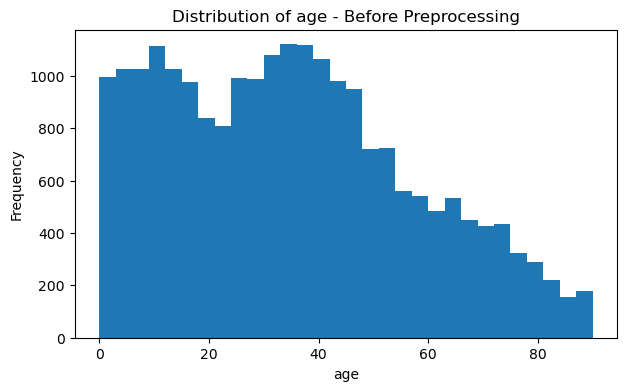

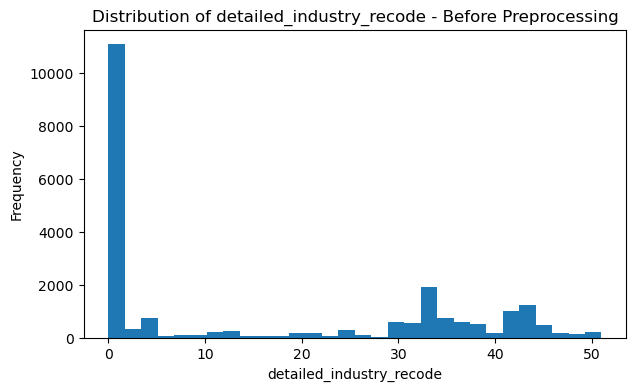

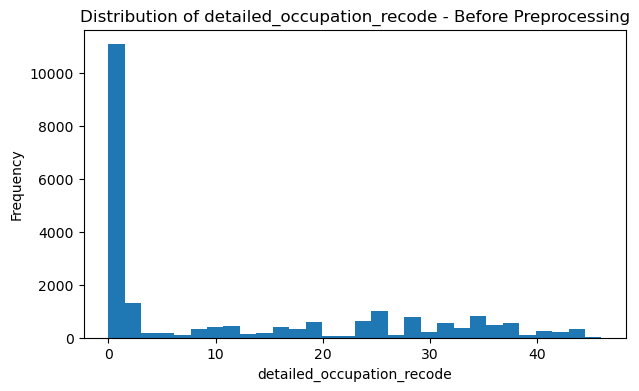

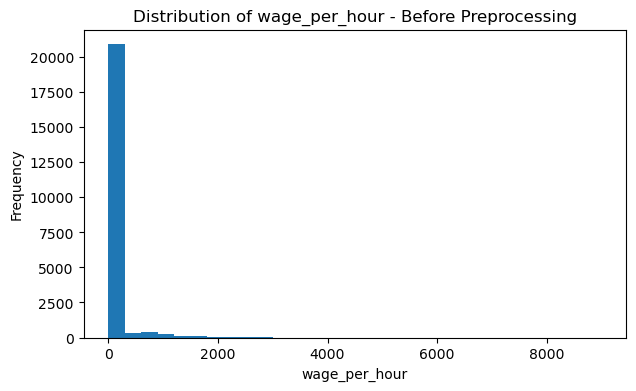

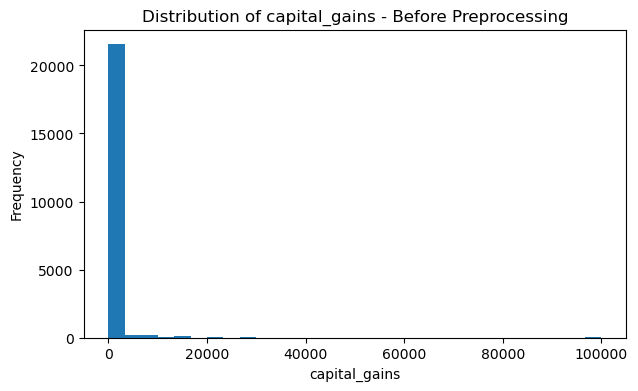

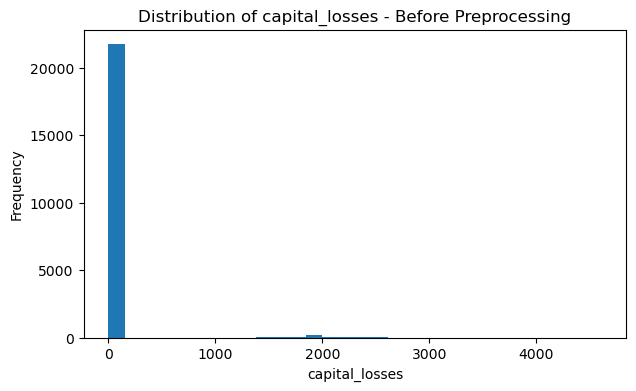

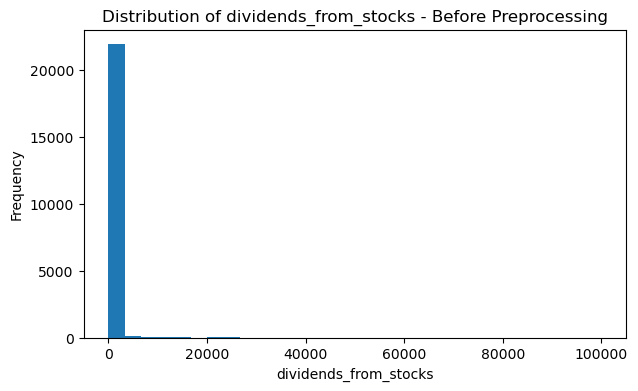

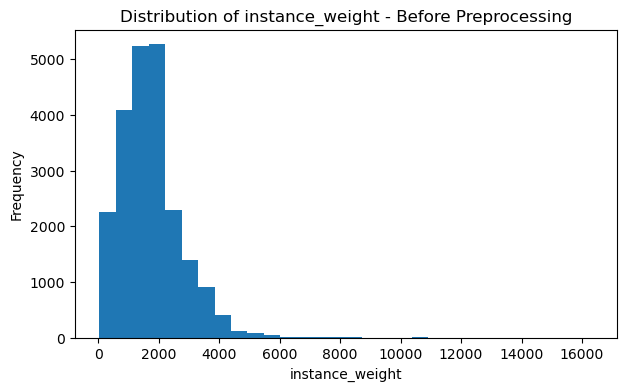

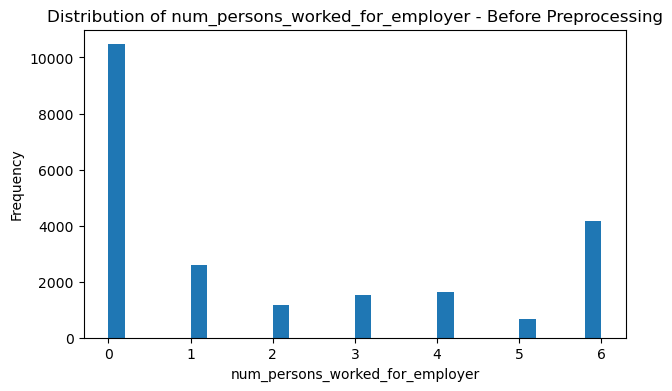

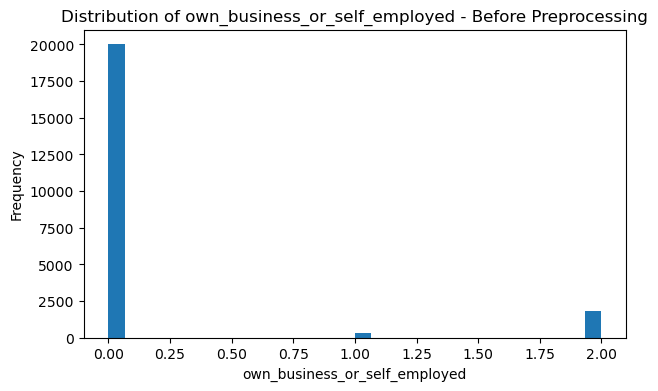

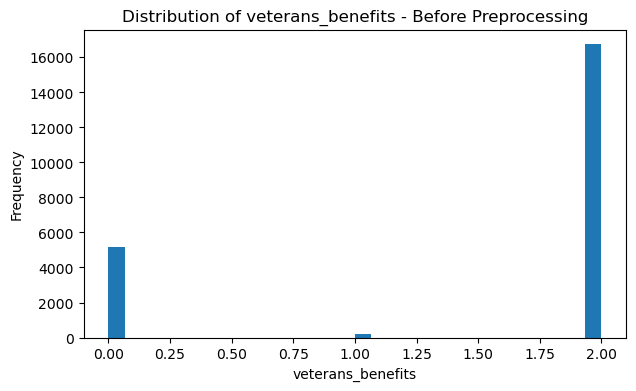

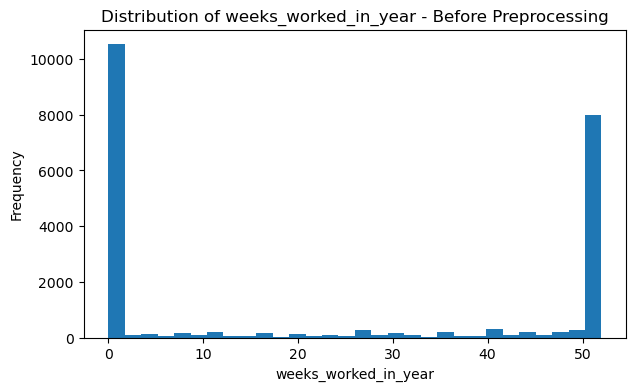

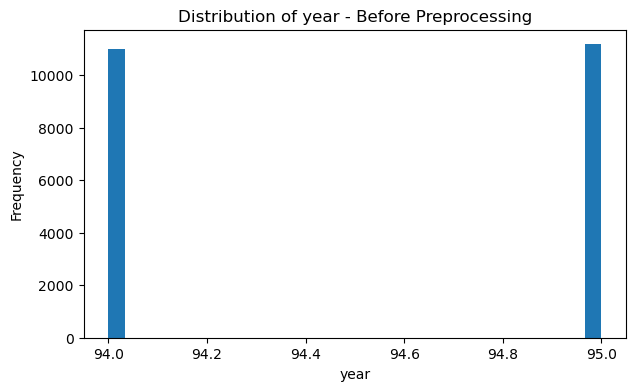

In [70]:
numeric_columns = census_df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    plt.figure(figsize=(7, 4))
    plt.hist(census_df[column].dropna(), bins=30)
    plt.title(f"Distribution of {column} - Before Preprocessing")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

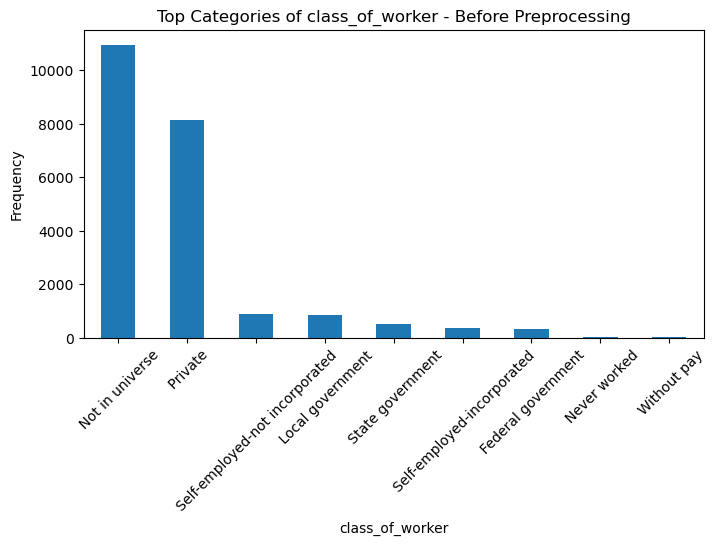

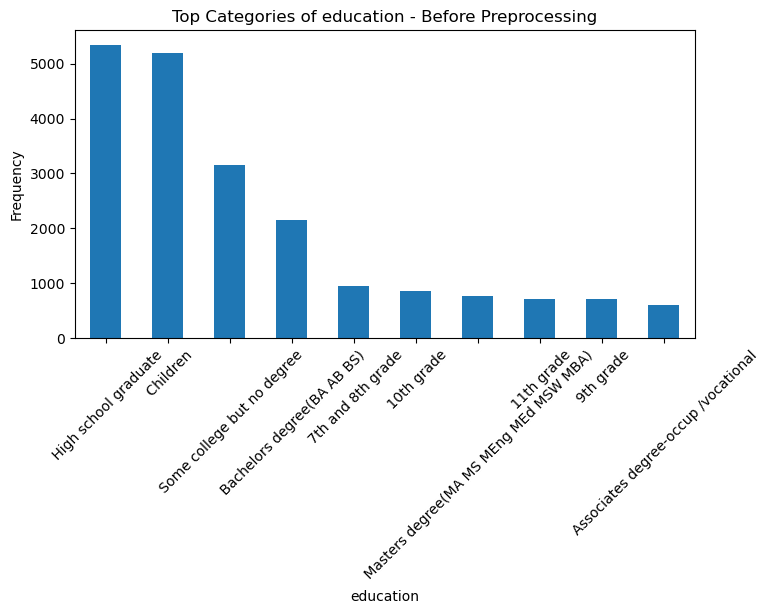

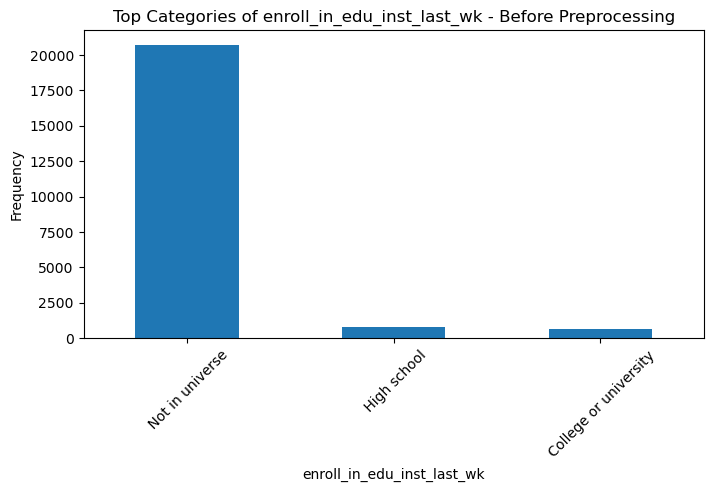

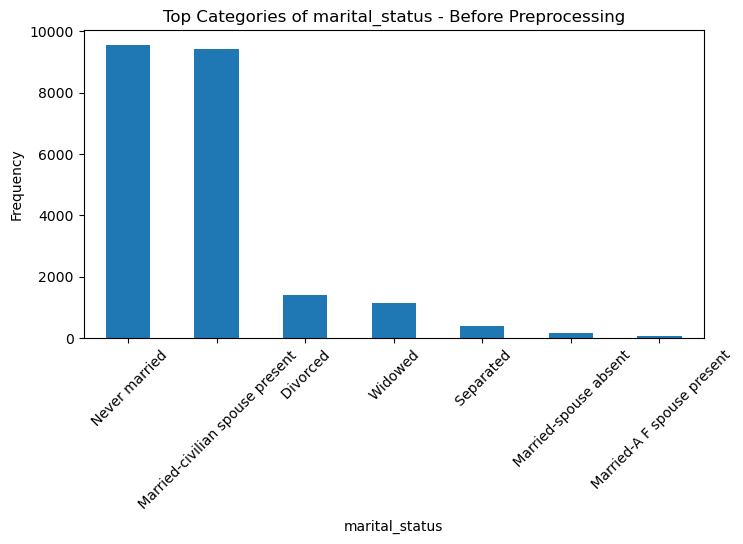

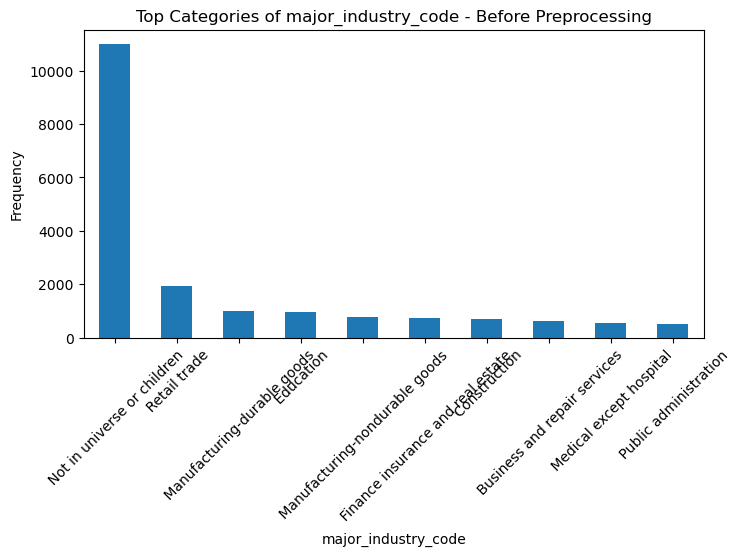

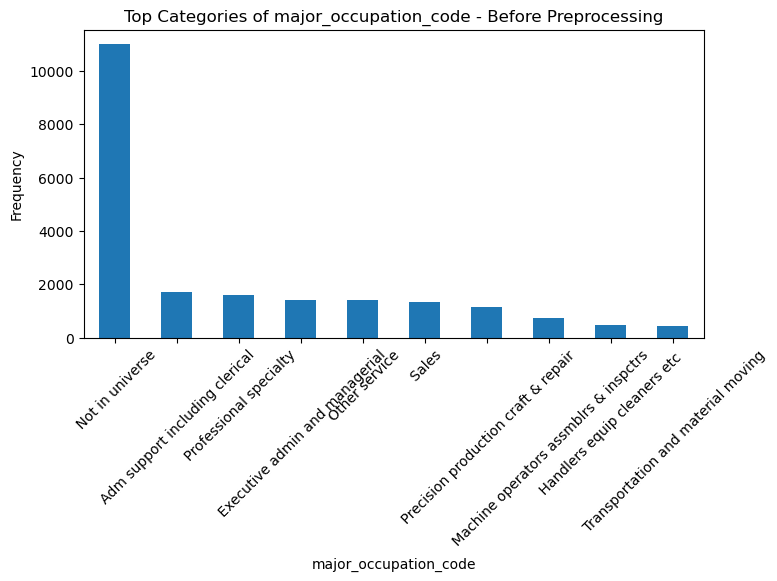

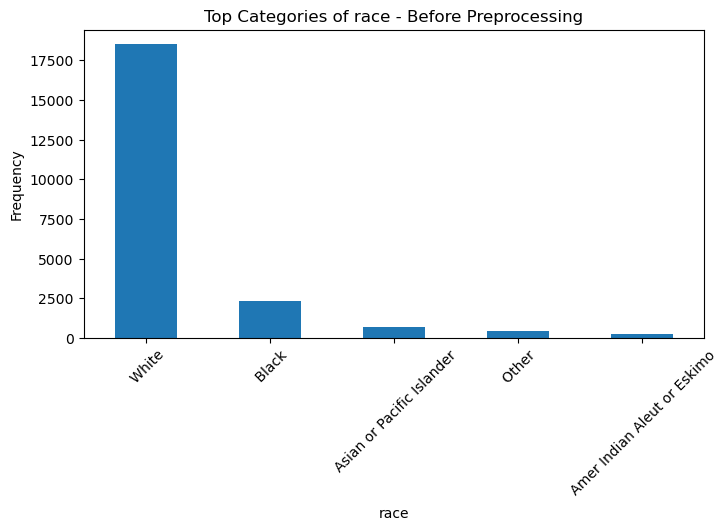

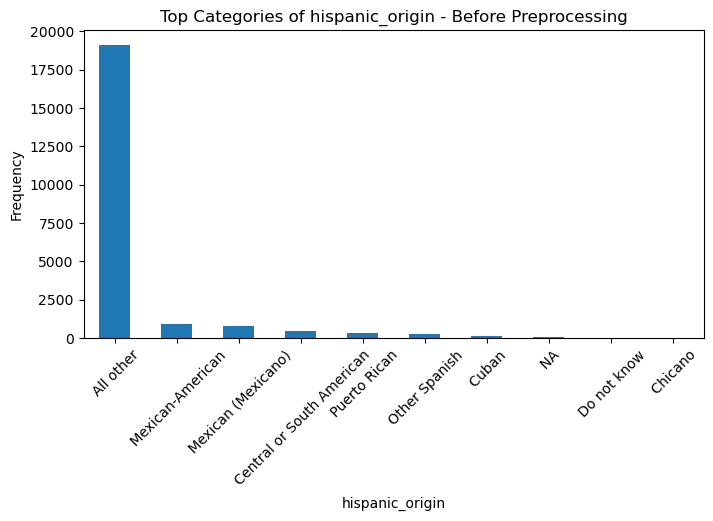

In [71]:
categorical_columns = census_df.select_dtypes(include='object').columns

for column in categorical_columns[:8]:
    plt.figure(figsize=(8, 4))
    census_df[column].value_counts().head(10).plot(kind='bar')
    plt.title(f"Top Categories of {column} - Before Preprocessing")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    plt.show()

In [73]:
## Data Quality Issues Identified


In [74]:
census_clean = census_df.copy()

In [75]:
for column in census_clean.select_dtypes(include='object').columns:
    census_clean[column] = census_clean[column].str.strip()

In [76]:
census_clean = census_clean.replace(
    ["?", " ?", "", " "],
    np.nan
)

In [77]:
before_duplicates = len(census_clean)

census_clean = census_clean.drop_duplicates()

after_duplicates = len(census_clean)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Rows before removing duplicates: 22150
Rows after removing duplicates: 22103
Duplicates removed: 47


In [78]:
census_clean.isnull().sum().sort_values(ascending=False)

migration_prev_res_in_sunbelt               11138
migration_code_change_in_msa                11138
migration_code_change_in_reg                11138
migration_code_move_within_reg              11138
country_of_birth_father                       695
country_of_birth_mother                       653
country_of_birth_self                         344
state_of_previous_residence                    70
major_industry_code                             1
major_occupation_code                           1
instance_weight                                 1
detailed_household_summary_in_household         1
detailed_household_and_family_stat              1
region_of_previous_residence                    1
dividends_from_stocks                           1
tax_filer_status                                1
enroll_in_edu_inst_last_wk                      1
marital_status                                  1
capital_losses                                  1
capital_gains                                   1


In [79]:
numeric_columns_clean = census_clean.select_dtypes(include=np.number).columns

for column in numeric_columns_clean:
    census_clean[column] = census_clean[column].fillna(
        census_clean[column].median()
    )

In [80]:
categorical_columns_clean = census_clean.select_dtypes(include='object').columns

for column in categorical_columns_clean:
    if census_clean[column].isnull().sum() > 0:
        census_clean[column] = census_clean[column].fillna(
            census_clean[column].mode()[0]
        )

In [81]:
census_clean.isnull().sum().sum()

0

In [82]:
census_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22103 entries, 0 to 22149
Data columns (total 42 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   age                                       22103 non-null  int64  
 1   class_of_worker                           22103 non-null  object 
 2   detailed_industry_recode                  22103 non-null  int64  
 3   detailed_occupation_recode                22103 non-null  int64  
 4   education                                 22103 non-null  object 
 5   wage_per_hour                             22103 non-null  int64  
 6   enroll_in_edu_inst_last_wk                22103 non-null  object 
 7   marital_status                            22103 non-null  object 
 8   major_industry_code                       22103 non-null  object 
 9   major_occupation_code                     22103 non-null  object 
 10  race                                   

In [83]:
census_clean.describe()

,age,detailed_industry_recode,detailed_occupation_recode,wage_per_hour,capital_gains,capital_losses,dividends_from_stocks,instance_weight,num_persons_worked_for_employer,own_business_or_self_employed,veterans_benefits,weeks_worked_in_year,year
count,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000
mean,34.586617,15.634891,11.481971,56.390626,427.474008,36.863638,181.564629,1733.670428,1.995385,0.179297,1.524770,23.491223,94.503913
std,22.233228,18.108566,14.455278,282.086273,4493.894382,272.682898,1932.700983,982.951549,2.374471,0.559081,0.845396,24.397662,0.499996
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,42.820000,0.000000,0.000000,0.000000,0.000000,94.000000
25%,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1060.150000,0.000000,0.000000,2.000000,0.000000,94.000000
50%,33.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1623.990000,1.000000,0.000000,2.000000,10.500000,95.000000
75%,50.000000,33.000000,26.000000,0.000000,0.000000,0.000000,0.000000,2179.700000,4.000000,0.000000,2.000000,52.000000,95.000000
max,90.000000,51.000000,46.000000,9000.000000,99999.000000,4608.000000,99999.000000,16349.200000,6.000000,2.000000,2.000000,52.000000,95.000000


In [84]:
## Encoding Categorical Features

In [85]:
census_encoded = pd.get_dummies(
    census_clean,
    columns=categorical_columns_clean,
    drop_first=True
)

In [86]:
census_encoded.head()

,age,detailed_industry_recode,detailed_occupation_recode,wage_per_hour,capital_gains,capital_losses,dividends_from_stocks,instance_weight,num_persons_worked_for_employer,own_business_or_self_employed,...,country_of_birth_self_United-States,country_of_birth_self_Vietnam,country_of_birth_self_Yugoslavia,citizenship_Foreign born- U S citizen by naturalization,citizenship_Native- Born abroad of American Parent(s),citizenship_Native- Born in Puerto Rico or U S Outlying,citizenship_Native- Born in the United States,fill_inc_questionnaire_for_veteran_admin_Not in universe,fill_inc_questionnaire_for_veteran_admin_Yes,income_class_50000+.
0,73,0,0,0,0.0,0.0,0.0,1700.09,0.0,0.0,...,True,False,False,False,False,False,True,True,False,False
1,58,4,34,0,0.0,0.0,0.0,1053.55,1.0,0.0,...,True,False,False,False,False,False,True,True,False,False
2,18,0,0,0,0.0,0.0,0.0,991.95,0.0,0.0,...,False,True,False,False,False,False,False,True,False,False
3,9,0,0,0,0.0,0.0,0.0,1758.14,0.0,0.0,...,True,False,False,False,False,False,True,True,False,False
4,10,0,0,0,0.0,0.0,0.0,1069.16,0.0,0.0,...,True,False,False,False,False,False,True,True,False,False


In [87]:
print("Shape before encoding:", census_clean.shape)
print("Shape after encoding:", census_encoded.shape)

Shape before encoding: (22103, 42)
Shape after encoding: (22103, 367)


In [88]:
census_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22103 entries, 0 to 22149
Columns: 367 entries, age to income_class_50000+.
dtypes: bool(354), float64(9), int64(4)
memory usage: 9.8 MB


In [89]:
census_encoded.describe()

,age,detailed_industry_recode,detailed_occupation_recode,wage_per_hour,capital_gains,capital_losses,dividends_from_stocks,instance_weight,num_persons_worked_for_employer,own_business_or_self_employed,veterans_benefits,weeks_worked_in_year,year
count,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000
mean,34.586617,15.634891,11.481971,56.390626,427.474008,36.863638,181.564629,1733.670428,1.995385,0.179297,1.524770,23.491223,94.503913
std,22.233228,18.108566,14.455278,282.086273,4493.894382,272.682898,1932.700983,982.951549,2.374471,0.559081,0.845396,24.397662,0.499996
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,42.820000,0.000000,0.000000,0.000000,0.000000,94.000000
25%,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1060.150000,0.000000,0.000000,2.000000,0.000000,94.000000
50%,33.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1623.990000,1.000000,0.000000,2.000000,10.500000,95.000000
75%,50.000000,33.000000,26.000000,0.000000,0.000000,0.000000,0.000000,2179.700000,4.000000,0.000000,2.000000,52.000000,95.000000
max,90.000000,51.000000,46.000000,9000.000000,99999.000000,4608.000000,99999.000000,16349.200000,6.000000,2.000000,2.000000,52.000000,95.000000


In [90]:
## EDA After Preprocessing

In [91]:
census_clean.isnull().sum().sum()

0

In [92]:
print("Duplicate rows after preprocessing:", census_clean.duplicated().sum())

Duplicate rows after preprocessing: 0


In [93]:
census_encoded.describe()

,age,detailed_industry_recode,detailed_occupation_recode,wage_per_hour,capital_gains,capital_losses,dividends_from_stocks,instance_weight,num_persons_worked_for_employer,own_business_or_self_employed,veterans_benefits,weeks_worked_in_year,year
count,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000,22103.000000
mean,34.586617,15.634891,11.481971,56.390626,427.474008,36.863638,181.564629,1733.670428,1.995385,0.179297,1.524770,23.491223,94.503913
std,22.233228,18.108566,14.455278,282.086273,4493.894382,272.682898,1932.700983,982.951549,2.374471,0.559081,0.845396,24.397662,0.499996
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,42.820000,0.000000,0.000000,0.000000,0.000000,94.000000
25%,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1060.150000,0.000000,0.000000,2.000000,0.000000,94.000000
50%,33.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1623.990000,1.000000,0.000000,2.000000,10.500000,95.000000
75%,50.000000,33.000000,26.000000,0.000000,0.000000,0.000000,0.000000,2179.700000,4.000000,0.000000,2.000000,52.000000,95.000000
max,90.000000,51.000000,46.000000,9000.000000,99999.000000,4608.000000,99999.000000,16349.200000,6.000000,2.000000,2.000000,52.000000,95.000000


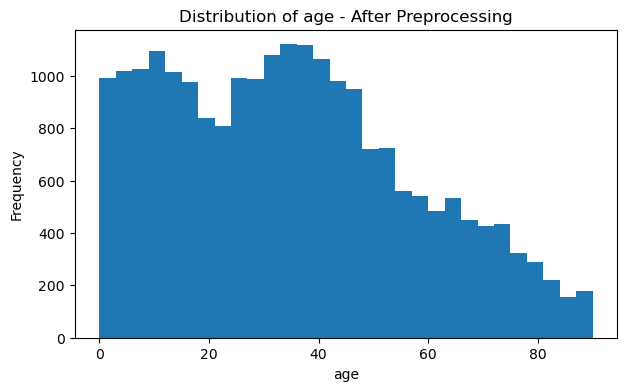

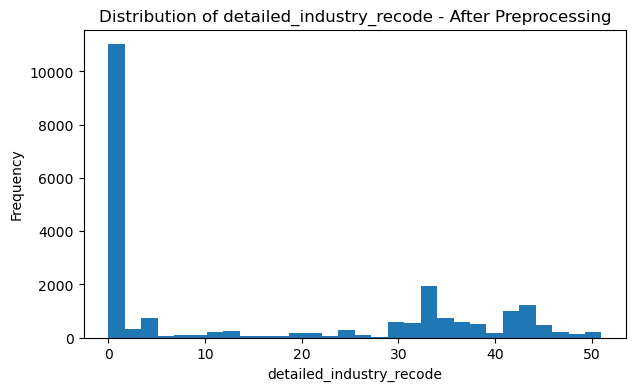

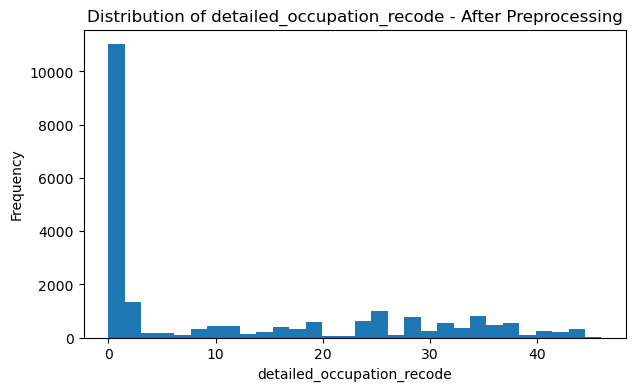

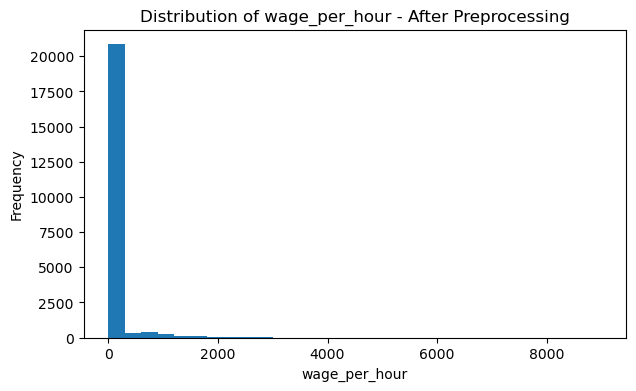

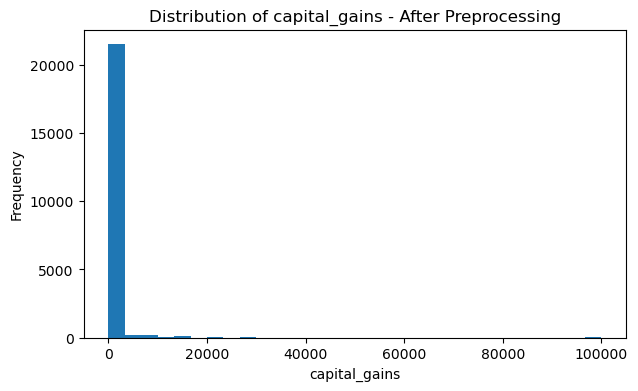

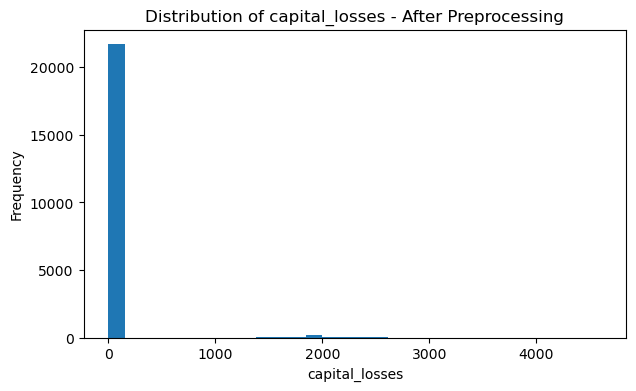

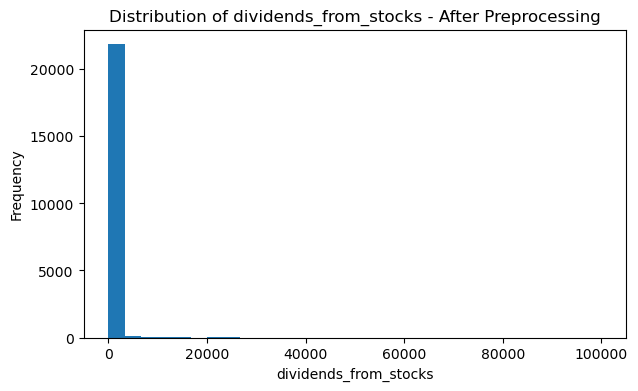

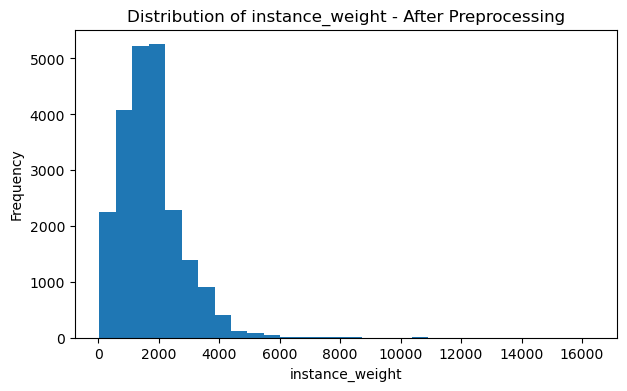

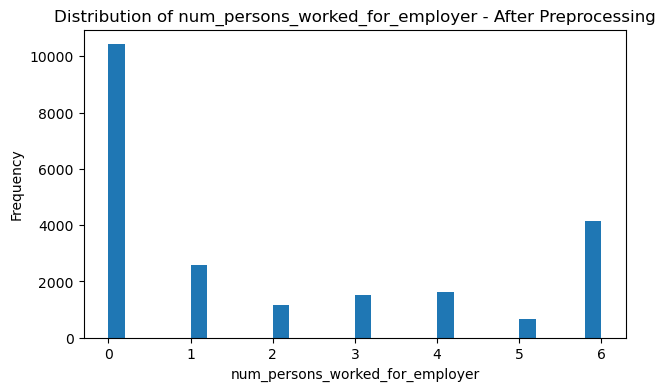

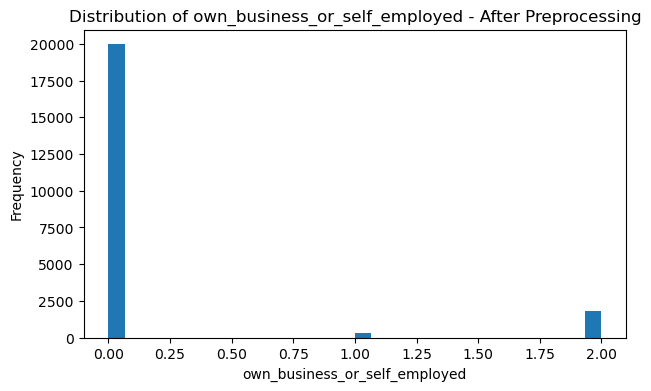

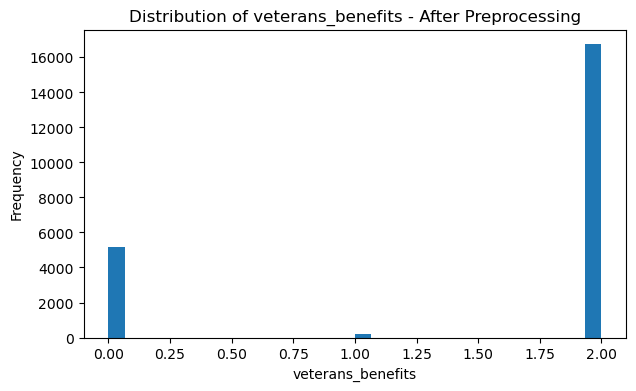

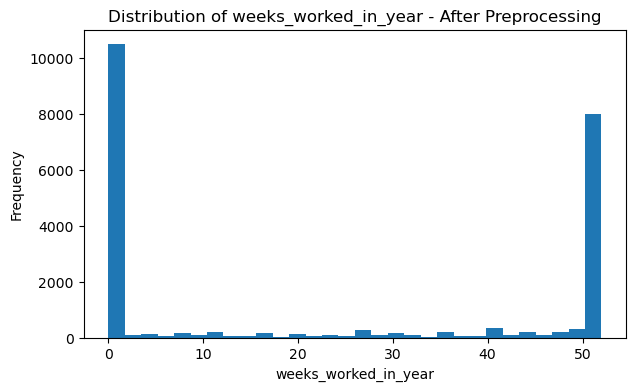

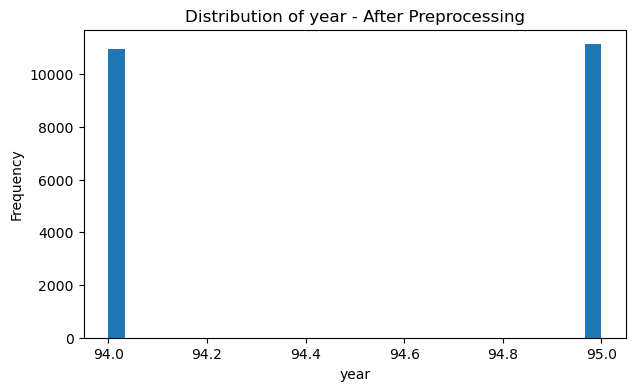

In [94]:
for column in numeric_columns_clean:
    plt.figure(figsize=(7, 4))
    plt.hist(census_clean[column], bins=30)
    plt.title(f"Distribution of {column} - After Preprocessing")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

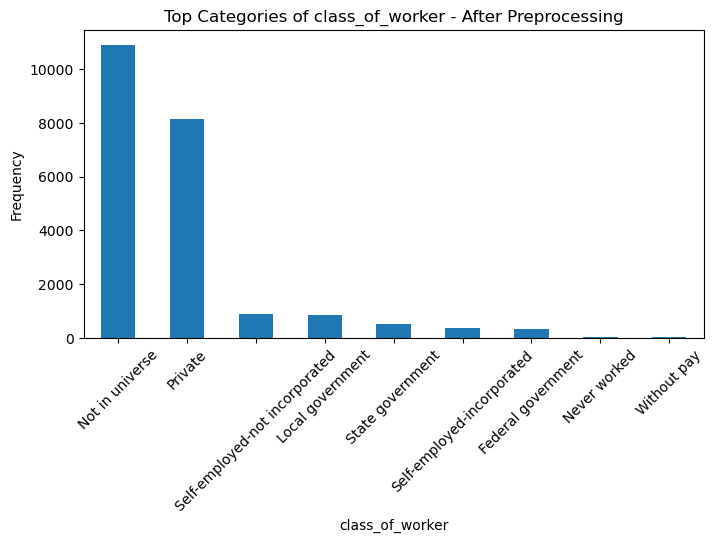

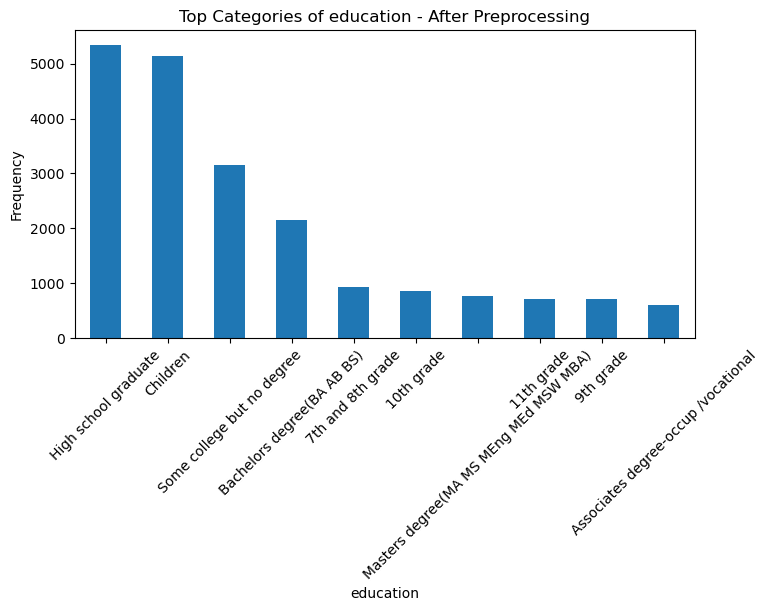

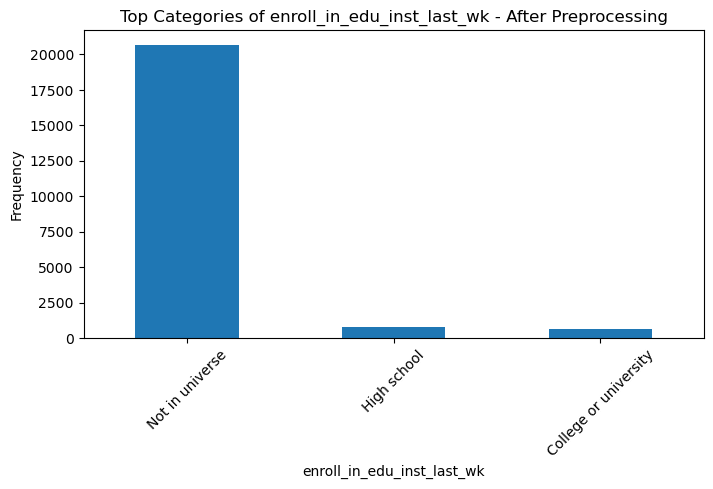

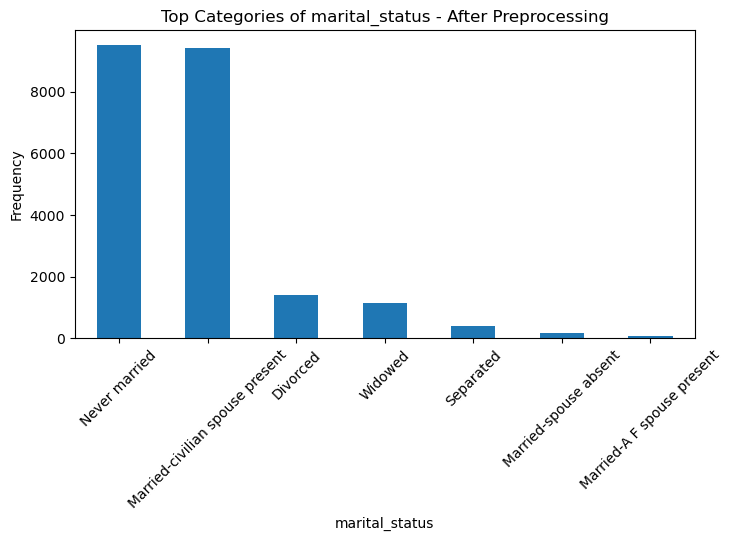

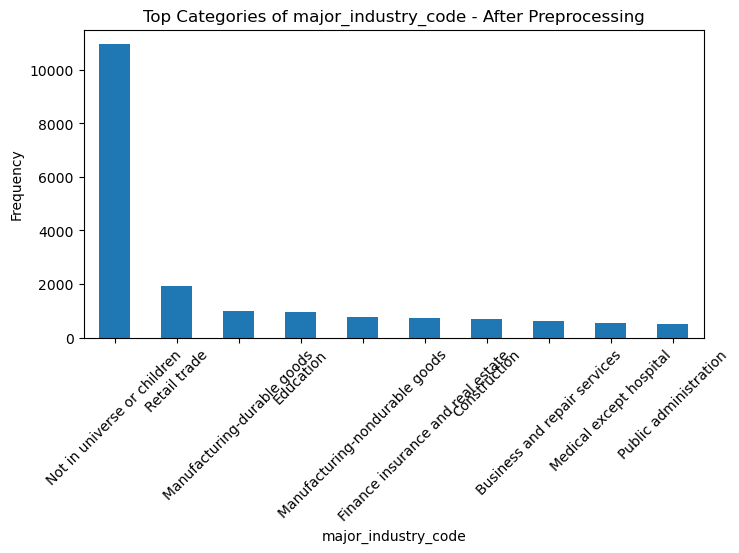

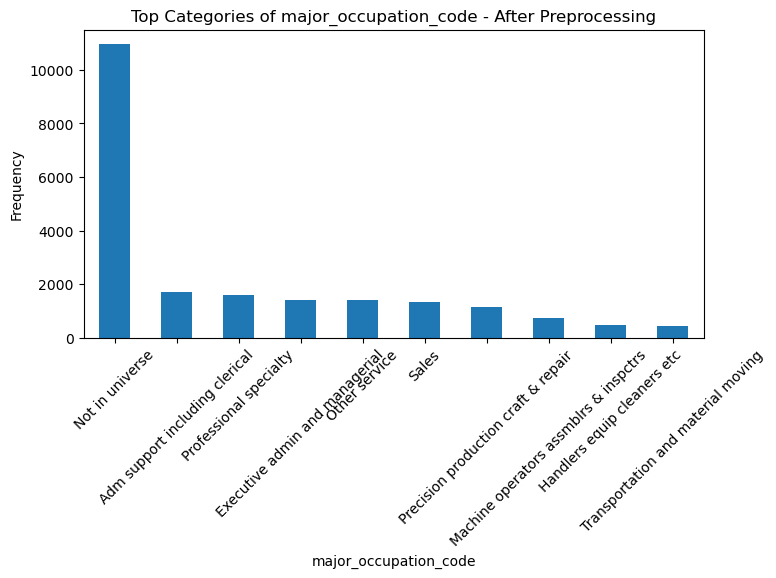

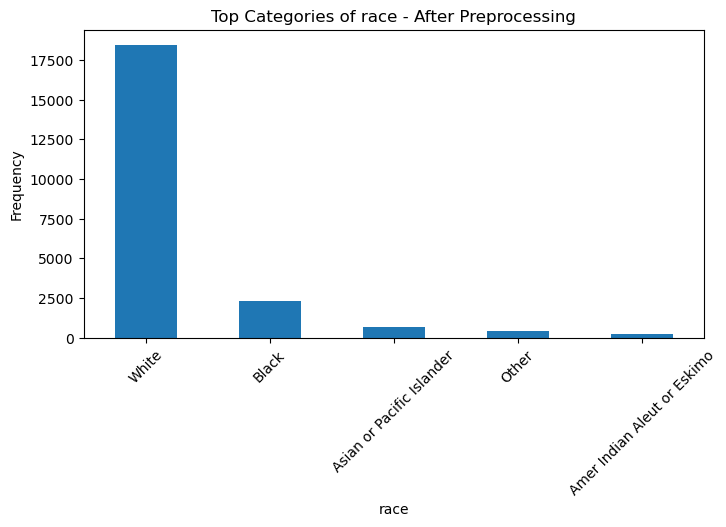

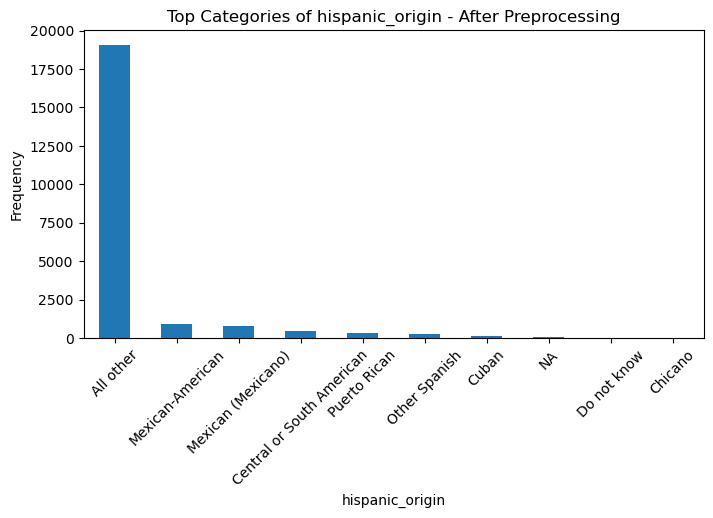

In [95]:
for column in categorical_columns_clean[:8]:
    plt.figure(figsize=(8, 4))
    census_clean[column].value_counts().head(10).plot(kind='bar')
    plt.title(f"Top Categories of {column} - After Preprocessing")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    plt.show()

In [96]:
## Comparison of EDA Before and After Preprocessing

In [97]:
print("Original dataset shape:", census_df.shape)
print("Cleaned dataset shape:", census_clean.shape)
print("Encoded dataset shape:", census_encoded.shape)

print("\nMissing values before preprocessing:",
      census_df.isnull().sum().sum())

print("Missing values after preprocessing:",
      census_clean.isnull().sum().sum())

print("\nDuplicate rows before preprocessing:",
      census_df.duplicated().sum())

print("Duplicate rows after preprocessing:",
      census_clean.duplicated().sum())

Original dataset shape: (22150, 42)
Cleaned dataset shape: (22103, 42)
Encoded dataset shape: (22103, 367)

Missing values before preprocessing: 36
Missing values after preprocessing: 0

Duplicate rows before preprocessing: 47
Duplicate rows after preprocessing: 0


In [98]:
## Final Preprocessed Dataset

In [99]:
census_encoded.head()

,age,detailed_industry_recode,detailed_occupation_recode,wage_per_hour,capital_gains,capital_losses,dividends_from_stocks,instance_weight,num_persons_worked_for_employer,own_business_or_self_employed,...,country_of_birth_self_United-States,country_of_birth_self_Vietnam,country_of_birth_self_Yugoslavia,citizenship_Foreign born- U S citizen by naturalization,citizenship_Native- Born abroad of American Parent(s),citizenship_Native- Born in Puerto Rico or U S Outlying,citizenship_Native- Born in the United States,fill_inc_questionnaire_for_veteran_admin_Not in universe,fill_inc_questionnaire_for_veteran_admin_Yes,income_class_50000+.
0,73,0,0,0,0.0,0.0,0.0,1700.09,0.0,0.0,...,True,False,False,False,False,False,True,True,False,False
1,58,4,34,0,0.0,0.0,0.0,1053.55,1.0,0.0,...,True,False,False,False,False,False,True,True,False,False
2,18,0,0,0,0.0,0.0,0.0,991.95,0.0,0.0,...,False,True,False,False,False,False,False,True,False,False
3,9,0,0,0,0.0,0.0,0.0,1758.14,0.0,0.0,...,True,False,False,False,False,False,True,True,False,False
4,10,0,0,0,0.0,0.0,0.0,1069.16,0.0,0.0,...,True,False,False,False,False,False,True,True,False,False


In [ ]:
# Brief Report

## Census-Income Dataset

The Census-Income dataset was analyzed to understand its structure,
data quality issues, and the importance of preprocessing in the data
science workflow. Initially, the dataset was inspected using shape,
information, descriptive statistics, missing-value analysis, duplicate
checking, and categorical value analysis.

The initial EDA helped identify potential data quality issues including
missing values, duplicate records, categorical variables, and possible
unusual numerical observations. Distribution plots were also generated
for numerical variables, while frequency plots were used to examine
categorical variables. This initial analysis provided an understanding
of the dataset before applying any preprocessing techniques.

For preprocessing, a copy of the original dataset was created so that
the original data remained unchanged. Unnecessary spaces were removed
from categorical values and obvious missing-value markers were converted
to missing values. Duplicate records were removed where present.
Missing numerical values were handled using the median, while missing
categorical values were replaced using the mode.

Categorical features cannot directly be used by many machine learning
algorithms in their original text form. Therefore, One-Hot Encoding was
applied to convert categorical variables into numerical features. The
number of columns increased after encoding because each categorical
category was represented by a separate numerical feature.

After preprocessing, EDA was performed again. Missing values were
checked to confirm that they had been handled, duplicate records were
checked again, and descriptive statistics and distribution plots were
generated. Comparing the results before and after preprocessing showed
the effect of data cleaning on the dataset.

Data filtering and preprocessing are important steps in the data
science workflow because poor-quality data can lead to inaccurate
analysis and unreliable machine learning results. Handling missing
values, duplicate records, inconsistent entries, and categorical
variables improves data quality and prepares the dataset for further
analysis and modeling. Overall, preprocessing transforms raw data into
a more consistent and usable form while EDA helps verify the quality
and characteristics of the data before and after these transformations.